In [1]:

import pandas as pd
import numpy as np
import os
import zipfile
from IPython.display import display

# Reproducible synthetic dataset
np.random.seed(42)

# Create a folder to store the five CSV files
output_folder = "/content/cinema_revenue_data"
os.makedirs(output_folder, exist_ok=True)

# ---------------------------------
# 1. CINEMAS DATASET
# ---------------------------------
cinemas = pd.DataFrame({
    "cinema_id": [f"C{i:02d}" for i in range(1, 9)],
    "cinema": [
        "SilverScreen Coimbatore",
        "SilverScreen Chennai",
        "SilverScreen Bengaluru",
        "SilverScreen Madurai",
        "SilverScreen Salem",
        "SilverScreen Trichy",
        "SilverScreen Kochi",
        "SilverScreen Hyderabad"
    ],
    "city": [
        "Coimbatore", "Chennai", "Bengaluru", "Madurai",
        "Salem", "Trichy", "Kochi", "Hyderabad"
    ],
    "screen_capacity": [150, 200, 180, 120, 140, 160, 170, 220]
})

# ---------------------------------
# 2. MOVIES DATASET
# ---------------------------------
movies = pd.DataFrame({
    "movie_id": [f"M{i:02d}" for i in range(1, 21)],
    "movie": [
        "Sky Warriors", "Love Beyond", "Code Red", "The Last Kingdom",
        "Magic Forest", "Silent Truth", "Ocean Mystery", "City Lights",
        "Final Mission", "Dream Journey", "Shadow Game", "Golden Days",
        "Space Explorer", "Hidden Secret", "Family Time", "Wild Earth",
        "Night Chase", "Broken Promise", "Future World", "The Champion"
    ],
    "genre": [
        "Action", "Romance", "Thriller", "Drama", "Animation",
        "Thriller", "Adventure", "Drama", "Action", "Romance",
        "Thriller", "Drama", "Sci-Fi", "Mystery", "Family",
        "Documentary", "Action", "Romance", "Sci-Fi", "Sports"
    ],
    "language": np.random.choice(
        ["Tamil", "English", "Hindi", "Telugu", "Malayalam"], 20
    ),
    "runtime_minutes": np.random.randint(90, 181, 20),
    "certification": np.random.choice(
        ["U", "UA", "A"], 20, p=[0.35, 0.50, 0.15]
    )
})

# Add inconsistent genre labels for data-cleaning practice
movies.loc[2, "genre"] = "action"
movies.loc[7, "genre"] = "DRAMA"
movies.loc[12, "genre"] = "Sci Fi"

# ---------------------------------
# 3. PRICING DATASET
# ---------------------------------
pricing_rows = []
base_prices = {"Standard": 180, "Premium": 250, "Recliner": 350}
offers = {"No Offer": 0, "Student": 0.10, "Weekend Deal": 0.15}

for seat_class, base_price in base_prices.items():
    for offer, discount in offers.items():
        pricing_rows.append({
            "seat_class": seat_class,
            "offer": offer,
            "ticket_price": base_price,
            "discount_percent": int(discount * 100)
        })

pricing = pd.DataFrame(pricing_rows)

# ---------------------------------
# 4. CALENDAR DATASET
# ---------------------------------
dates = pd.date_range("2026-01-01", periods=120, freq="D")

calendar = pd.DataFrame({"show_date": dates})
calendar["weekday"] = calendar["show_date"].dt.day_name()
calendar["holiday"] = (
    calendar["weekday"].isin(["Saturday", "Sunday"])
).astype(int)

# A synthetic observation-period week, used for trend analysis
calendar["release_week"] = (
    ((calendar["show_date"] - calendar["show_date"].min()).dt.days // 7) + 1
).map(lambda week: f"Week {week}")

# Add a few fictional holidays
holiday_dates = pd.to_datetime([
    "2026-01-14", "2026-01-26", "2026-03-04"
])
calendar.loc[
    calendar["show_date"].isin(holiday_dates), "holiday"
] = 1

# ---------------------------------
# 5. BOOKINGS DATASET
# ---------------------------------
n = 1500

bookings = pd.DataFrame({
    "booking_id": [f"B{i:05d}" for i in range(1, n + 1)],
    "cinema_id": np.random.choice(cinemas["cinema_id"], n),
    "movie_id": np.random.choice(movies["movie_id"], n),
    "show_date": np.random.choice(dates, n),
    "show_time": np.random.choice(
        ["09:00", "12:00", "15:00", "18:00", "21:00"], n
    ),
    "screen_id": np.random.choice(
        ["Screen 1", "Screen 2", "Screen 3"], n
    ),
    "seat_class": np.random.choice(
        ["Standard", "Premium", "Recliner"], n,
        p=[0.60, 0.30, 0.10]
    ),
    "offer": np.random.choice(
        ["No Offer", "Student", "Weekend Deal"], n,
        p=[0.60, 0.20, 0.20]
    ),
    "tickets_sold": np.random.randint(20, 151, n)
})

# Calculate revenue using the pricing table
bookings = bookings.merge(
    pricing, on=["seat_class", "offer"], how="left"
)
bookings["revenue"] = (
    bookings["tickets_sold"]
    * bookings["ticket_price"]
    * (1 - bookings["discount_percent"] / 100)
).round(2)

# Remove helper pricing columns from bookings
bookings = bookings.drop(
    columns=["ticket_price", "discount_percent"]
)

# Add intentional data-quality problems for cleaning practice
bookings.loc[5, "show_time"] = np.nan
bookings.loc[10, "show_time"] = np.nan
bookings.loc[20, "tickets_sold"] = -5

# Create some capacity mismatches for practice
bookings.loc[30, "tickets_sold"] = 250
bookings.loc[30, "revenue"] = (
    bookings.loc[30, "revenue"] *
    250 / max(1, bookings.loc[30, "tickets_sold"])
)

# Duplicate a booking row intentionally
bookings = pd.concat(
    [bookings, bookings.iloc[[0]]], ignore_index=True
)

# ---------------------------------
# SAVE ALL FIVE CSV FILES
# ---------------------------------
datasets = {
    "bookings.csv": bookings,
    "movies.csv": movies,
    "cinemas.csv": cinemas,
    "pricing.csv": pricing,
    "calendar.csv": calendar
}

for filename, dataframe in datasets.items():
    dataframe.to_csv(
        os.path.join(output_folder, filename), index=False
    )
    print(f"Created {filename}: {dataframe.shape[0]} rows")

# Preview the bookings data
print("\nBookings dataset preview:")
display(bookings.head())

# Package the files into one downloadable ZIP
zip_path = "/content/CH29_Cinema_Datasets.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for filename in datasets:
        zip_file.write(
            os.path.join(output_folder, filename),
            arcname=filename
        )

print("\nAll five synthetic CSV files were created successfully!")
print("ZIP file:", zip_path)


Created bookings.csv: 1501 rows
Created movies.csv: 20 rows
Created cinemas.csv: 8 rows
Created pricing.csv: 9 rows
Created calendar.csv: 120 rows

Bookings dataset preview:


,booking_id,cinema_id,movie_id,show_date,show_time,screen_id,seat_class,offer,tickets_sold,revenue
0,B00001,C02,M10,2026-04-10,09:00,Screen 3,Standard,No Offer,120,21600.0
1,B00002,C04,M17,2026-02-25,15:00,Screen 3,Standard,Weekend Deal,103,15759.0
2,B00003,C02,M09,2026-04-17,09:00,Screen 3,Premium,No Offer,80,20000.0
3,B00004,C02,M19,2026-03-25,15:00,Screen 2,Standard,Weekend Deal,144,22032.0
4,B00005,C06,M14,2026-03-23,18:00,Screen 2,Standard,No Offer,90,16200.0



All five synthetic CSV files were created successfully!
ZIP file: /content/CH29_Cinema_Datasets.zip


In [2]:

from google.colab import files
files.download("/content/CH29_Cinema_Datasets.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Data Cleaning and Preprocessing

In [3]:

import pandas as pd

bookings = pd.read_csv("bookings.csv")
movies = pd.read_csv("movies.csv")
cinemas = pd.read_csv("cinemas.csv")
pricing = pd.read_csv("pricing.csv")
calendar = pd.read_csv("calendar.csv")

datasets = {
    "Bookings": bookings,
    "Movies": movies,
    "Cinemas": cinemas,
    "Pricing": pricing,
    "Calendar": calendar
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", list(df.columns))



--- Bookings ---
Rows and columns: (1501, 10)
Missing values: 2
Duplicate rows: 1
Columns: ['booking_id', 'cinema_id', 'movie_id', 'show_date', 'show_time', 'screen_id', 'seat_class', 'offer', 'tickets_sold', 'revenue']

--- Movies ---
Rows and columns: (20, 6)
Missing values: 0
Duplicate rows: 0
Columns: ['movie_id', 'movie', 'genre', 'language', 'runtime_minutes', 'certification']

--- Cinemas ---
Rows and columns: (8, 4)
Missing values: 0
Duplicate rows: 0
Columns: ['cinema_id', 'cinema', 'city', 'screen_capacity']

--- Pricing ---
Rows and columns: (9, 4)
Missing values: 0
Duplicate rows: 0
Columns: ['seat_class', 'offer', 'ticket_price', 'discount_percent']

--- Calendar ---
Rows and columns: (120, 4)
Missing values: 0
Duplicate rows: 0
Columns: ['show_date', 'weekday', 'holiday', 'release_week']


In [4]:

import os
import zipfile
import pandas as pd

clean_folder = "/content/CH29_Cleaned_Data"
os.makedirs(clean_folder, exist_ok=True)

# Work on copies of the original data
b = bookings.copy()
m = movies.copy()
c = cinemas.copy()
p = pricing.copy()
cal = calendar.copy()

# 1. Convert dates to consistent datetime format
b["show_date"] = pd.to_datetime(b["show_date"], errors="coerce")
cal["show_date"] = pd.to_datetime(cal["show_date"], errors="coerce")

# 2. Remove duplicate bookings
b = b.drop_duplicates(subset=["booking_id"], keep="first")

# 3. Handle missing showtimes using the most common time
b["show_time"] = b["show_time"].fillna(
    b["show_time"].mode().iloc[0]
)

# 4. Remove rows with missing essential information
b = b.dropna(
    subset=["booking_id", "cinema_id", "movie_id", "show_date"]
)

# 5. Remove invalid ticket counts
b = b[b["tickets_sold"] > 0]

# 6. Standardize genre labels
m["genre"] = (
    m["genre"]
    .astype(str)
    .str.strip()
    .str.title()
    .replace({"Sci Fi": "Sci-Fi"})
)

# 7. Remove invalid cinema capacities
c = c[c["screen_capacity"] > 0]

# 8. Remove bookings referring to unknown cinemas or movies
b = b[b["cinema_id"].isin(c["cinema_id"])]
b = b[b["movie_id"].isin(m["movie_id"])]

# 9. Check bookings against cinema capacity
b = b.merge(
    c[["cinema_id", "screen_capacity"]],
    on="cinema_id",
    how="left"
)

capacity_issues = (b["tickets_sold"] > b["screen_capacity"]).sum()
print("Bookings exceeding cinema capacity:", capacity_issues)

# Remove impossible records rather than silently changing ticket counts
b = b[b["tickets_sold"] <= b["screen_capacity"]]
b = b.drop(columns=["screen_capacity"])

# 10. Recalculate revenue from the pricing table
# This keeps revenue consistent with ticket count and offer discount.
b = b.drop(columns=["revenue"], errors="ignore")
b = b.merge(
    p[["seat_class", "offer", "ticket_price", "discount_percent"]],
    on=["seat_class", "offer"],
    how="left",
    validate="many_to_one"
)

b["revenue"] = (
    b["tickets_sold"]
    * b["ticket_price"]
    * (1 - b["discount_percent"] / 100)
).round(2)

# 11. Save cleaned bookings without helper pricing columns
b = b.drop(columns=["ticket_price", "discount_percent"])

# Save all five cleaned datasets
clean_datasets = {
    "bookings_cleaned.csv": b,
    "movies_cleaned.csv": m,
    "cinemas_cleaned.csv": c,
    "pricing_cleaned.csv": p,
    "calendar_cleaned.csv": cal
}

for filename, df in clean_datasets.items():
    df.to_csv(os.path.join(clean_folder, filename), index=False)
    print(f"Saved {filename}: {len(df)} rows")

# Create a ZIP for download
zip_path = "/content/CH29_Cleaned_Data.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in clean_datasets:
        z.write(
            os.path.join(clean_folder, filename),
            arcname=filename
        )

print("\nCleaning completed!")
print("Bookings remaining:", len(b))
print("Missing showtimes:", b["show_time"].isna().sum())
print("Duplicate booking IDs:", b["booking_id"].duplicated().sum())


Bookings exceeding cinema capacity: 48
Saved bookings_cleaned.csv: 1451 rows
Saved movies_cleaned.csv: 20 rows
Saved cinemas_cleaned.csv: 8 rows
Saved pricing_cleaned.csv: 9 rows
Saved calendar_cleaned.csv: 120 rows

Cleaning completed!
Bookings remaining: 1451
Missing showtimes: 0
Duplicate booking IDs: 0


In [5]:

from google.colab import files
files.download("/content/CH29_Cleaned_Data.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Exploratory Data Analysis (EDA)

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from IPython.display import display

folder = "/content/CH29_Cleaned_Data"

bookings = pd.read_csv(f"{folder}/bookings_cleaned.csv")
movies = pd.read_csv(f"{folder}/movies_cleaned.csv")
cinemas = pd.read_csv(f"{folder}/cinemas_cleaned.csv")
pricing = pd.read_csv(f"{folder}/pricing_cleaned.csv")
calendar = pd.read_csv(f"{folder}/calendar_cleaned.csv")

# Convert date columns
bookings["show_date"] = pd.to_datetime(bookings["show_date"])
calendar["show_date"] = pd.to_datetime(calendar["show_date"])

# Combine bookings with movie and cinema details
df = bookings.merge(
    movies[["movie_id", "movie", "genre", "language"]],
    on="movie_id", how="left"
)

df = df.merge(
    cinemas[["cinema_id", "cinema", "city", "screen_capacity"]],
    on="cinema_id", how="left"
)

df = df.merge(
    calendar[["show_date", "weekday", "holiday", "release_week"]],
    on="show_date", how="left"
)

# Calculate occupancy for each booking record
df["occupancy_percent"] = (
    df["tickets_sold"] / df["screen_capacity"] * 100
).round(2)

# Classify weekends
df["day_type"] = np.where(
    df["weekday"].isin(["Saturday", "Sunday"]),
    "Weekend", "Weekday"
)

print("EDA dataset shape:", df.shape)
print("\nDataset preview:")
display(df.head())

print("\nSummary statistics:")
display(df[["tickets_sold", "revenue", "occupancy_percent"]].describe())


EDA dataset shape: (1451, 21)

Dataset preview:


,booking_id,cinema_id,movie_id,show_date,show_time,screen_id,seat_class,offer,tickets_sold,revenue,...,genre,language,cinema,city,screen_capacity,weekday,holiday,release_week,occupancy_percent,day_type
0,B00001,C02,M10,2026-04-10,09:00,Screen 3,Standard,No Offer,120,21600.0,...,Romance,Malayalam,SilverScreen Chennai,Chennai,200,Friday,0,Week 15,60.00,Weekday
1,B00002,C04,M17,2026-02-25,15:00,Screen 3,Standard,Weekend Deal,103,15759.0,...,Action,Telugu,SilverScreen Madurai,Madurai,120,Wednesday,0,Week 8,85.83,Weekday
2,B00003,C02,M09,2026-04-17,09:00,Screen 3,Premium,No Offer,80,20000.0,...,Action,Hindi,SilverScreen Chennai,Chennai,200,Friday,0,Week 16,40.00,Weekday
3,B00004,C02,M19,2026-03-25,15:00,Screen 2,Standard,Weekend Deal,144,22032.0,...,Sci-Fi,Tamil,SilverScreen Chennai,Chennai,200,Wednesday,0,Week 12,72.00,Weekday
4,B00005,C06,M14,2026-03-23,18:00,Screen 2,Standard,No Offer,90,16200.0,...,Mystery,English,SilverScreen Trichy,Trichy,160,Monday,0,Week 12,56.25,Weekday



Summary statistics:


,tickets_sold,revenue,occupancy_percent
count,1451.000000,1451.000000,1451.000000
mean,83.342522,17298.459338,50.910420
std,37.040972,9141.771158,23.742418
min,20.000000,3060.000000,9.090000
25%,52.000000,10080.000000,30.530000
50%,83.000000,16250.000000,50.560000
75%,114.000000,22500.000000,69.275000
max,150.000000,51800.000000,100.000000


,genre,total_revenue,tickets_sold
0,Action,4956543.5,23633
7,Romance,4004812.5,19125
4,Drama,3984576.5,19244
8,Sci-Fi,2477117.5,12354
10,Thriller,2260442.5,10965
6,Mystery,1397300.0,6738
2,Animation,1340560.5,6502
5,Family,1317447.0,6340
9,Sports,1227752.0,5973
1,Adventure,1202226.5,5606


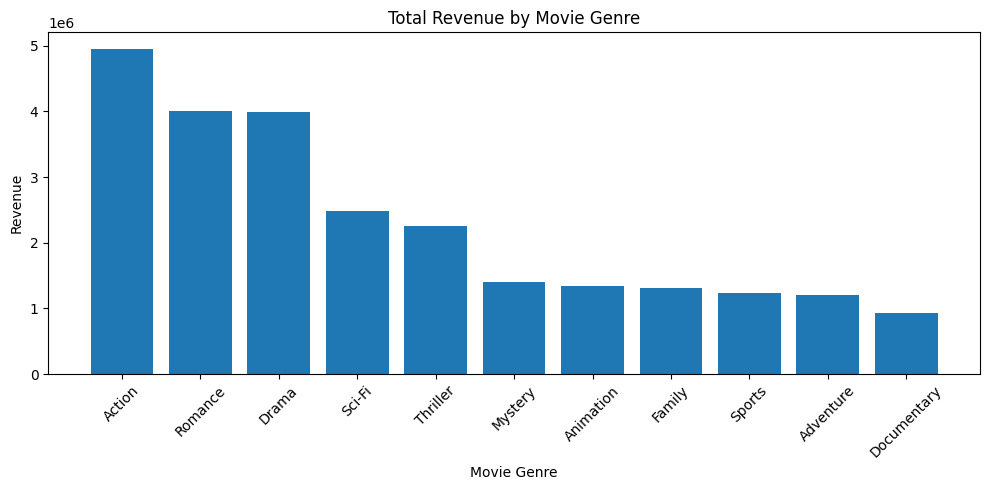

In [7]:

genre_revenue = (
    df.groupby("genre", as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        tickets_sold=("tickets_sold", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(genre_revenue)

plt.figure(figsize=(10, 5))
plt.bar(genre_revenue["genre"], genre_revenue["total_revenue"])
plt.title("Total Revenue by Movie Genre")
plt.xlabel("Movie Genre")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,show_time,tickets_sold,revenue,booking_records,average_occupancy_percent
0,09:00,24128,4772726.0,289,50.91
1,12:00,22119,4676142.0,275,48.88
2,15:00,24688,5215719.0,303,49.81
3,18:00,24400,5070264.0,276,54.06
4,21:00,25595,5365213.5,308,50.99


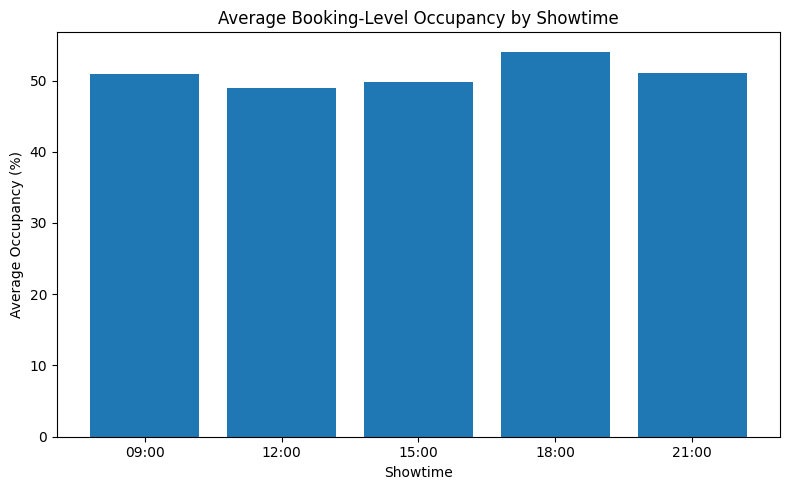

In [8]:

showtime_analysis = (
    df.groupby("show_time", as_index=False)
    .agg(
        tickets_sold=("tickets_sold", "sum"),
        revenue=("revenue", "sum"),
        booking_records=("booking_id", "count")
    )
)

# Each row represents a booking record, not necessarily a unique show.
showtime_analysis["average_occupancy_percent"] = (
    df.groupby("show_time")["occupancy_percent"]
    .mean()
    .values
).round(2)

display(showtime_analysis)

plt.figure(figsize=(8, 5))
plt.bar(
    showtime_analysis["show_time"],
    showtime_analysis["average_occupancy_percent"]
)
plt.title("Average Booking-Level Occupancy by Showtime")
plt.xlabel("Showtime")
plt.ylabel("Average Occupancy (%)")
plt.tight_layout()
plt.show()


,day_type,total_revenue,tickets_sold,average_occupancy
0,Weekday,18193043.0,87506,51.22
1,Weekend,6907021.5,33424,50.11


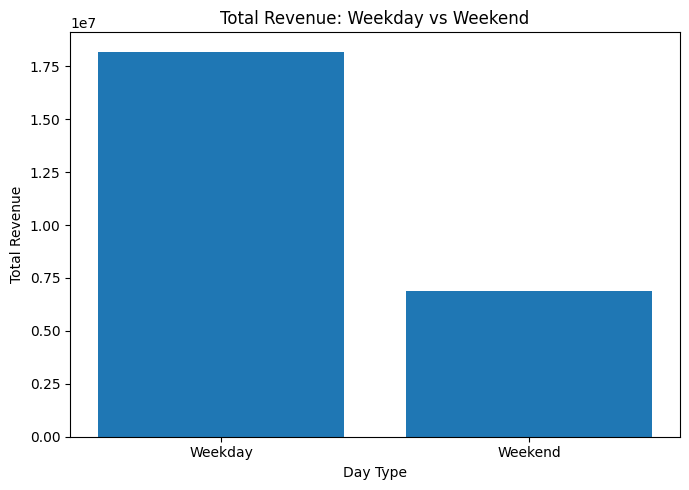

In [9]:

weekend_analysis = (
    df.groupby("day_type", as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        tickets_sold=("tickets_sold", "sum"),
        average_occupancy=("occupancy_percent", "mean")
    )
)

weekend_analysis["average_occupancy"] = (
    weekend_analysis["average_occupancy"].round(2)
)

display(weekend_analysis)

plt.figure(figsize=(7, 5))
plt.bar(
    weekend_analysis["day_type"],
    weekend_analysis["total_revenue"]
)
plt.title("Total Revenue: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


,cinema,city,total_revenue,tickets_sold,average_occupancy
2,SilverScreen Coimbatore,Coimbatore,3620435.0,17214,57.09
4,SilverScreen Kochi,Kochi,3371590.5,16130,51.85
7,SilverScreen Trichy,Trichy,3316166.0,16107,54.12
6,SilverScreen Salem,Salem,3227445.0,15354,58.96
3,SilverScreen Hyderabad,Hyderabad,3197937.0,15207,36.57
0,SilverScreen Bengaluru,Bengaluru,3182857.5,15549,48.26
1,SilverScreen Chennai,Chennai,2985097.5,14456,41.30
5,SilverScreen Madurai,Madurai,2198536.0,10913,59.83


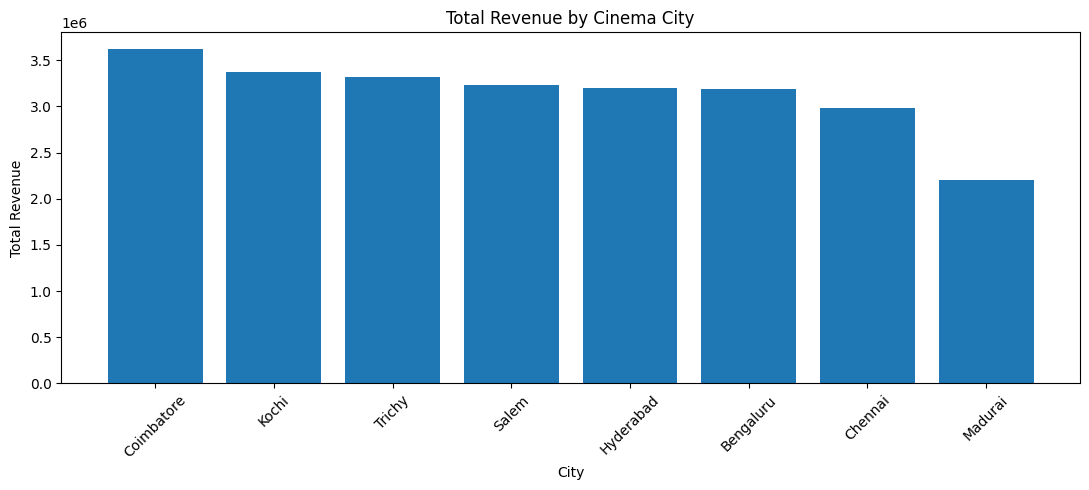

In [10]:

cinema_analysis = (
    df.groupby(["cinema", "city"], as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        tickets_sold=("tickets_sold", "sum"),
        average_occupancy=("occupancy_percent", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

cinema_analysis["average_occupancy"] = (
    cinema_analysis["average_occupancy"].round(2)
)

display(cinema_analysis)

plt.figure(figsize=(11, 5))
plt.bar(cinema_analysis["city"], cinema_analysis["total_revenue"])
plt.title("Total Revenue by Cinema City")
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,offer,total_revenue,tickets_sold,booking_records,average_revenue_per_ticket
0,No Offer,16630220.0,76119,905,218.48
1,Student,4135176.0,21377,260,193.44
2,Weekend Deal,4334668.5,23434,286,184.97


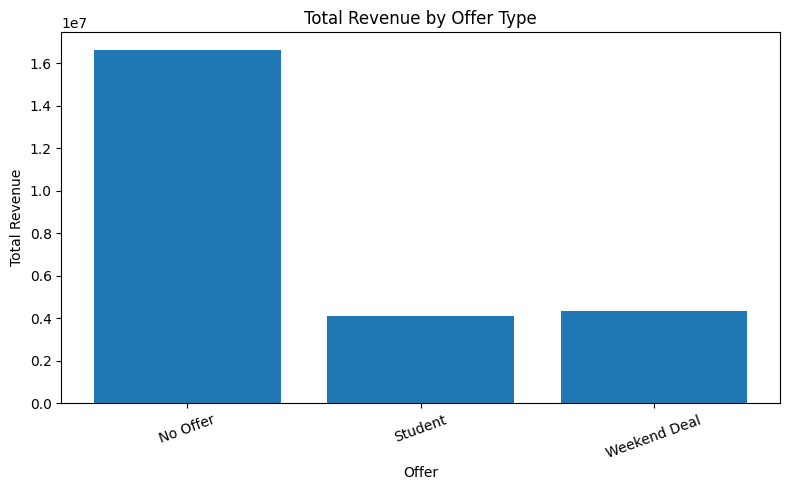

In [11]:

offer_analysis = (
    df.groupby("offer", as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        tickets_sold=("tickets_sold", "sum"),
        booking_records=("booking_id", "count"),
        average_revenue_per_ticket=("revenue", "sum")
    )
)

offer_analysis["average_revenue_per_ticket"] = (
    offer_analysis["average_revenue_per_ticket"]
    / offer_analysis["tickets_sold"]
).round(2)

display(offer_analysis)

plt.figure(figsize=(8, 5))
plt.bar(offer_analysis["offer"], offer_analysis["total_revenue"])
plt.title("Total Revenue by Offer Type")
plt.xlabel("Offer")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


,release_week,total_revenue,tickets_sold
0,Week 1,1236758.5,6057
10,Week 2,1659090.0,8164
11,Week 3,1623850.5,7804
12,Week 4,1346246.0,6489
13,Week 5,1447899.5,7117
14,Week 6,1484409.0,6858
15,Week 7,1735055.0,8153
16,Week 8,1488724.5,7190
17,Week 9,1511601.5,7051
1,Week 10,1539268.5,7152


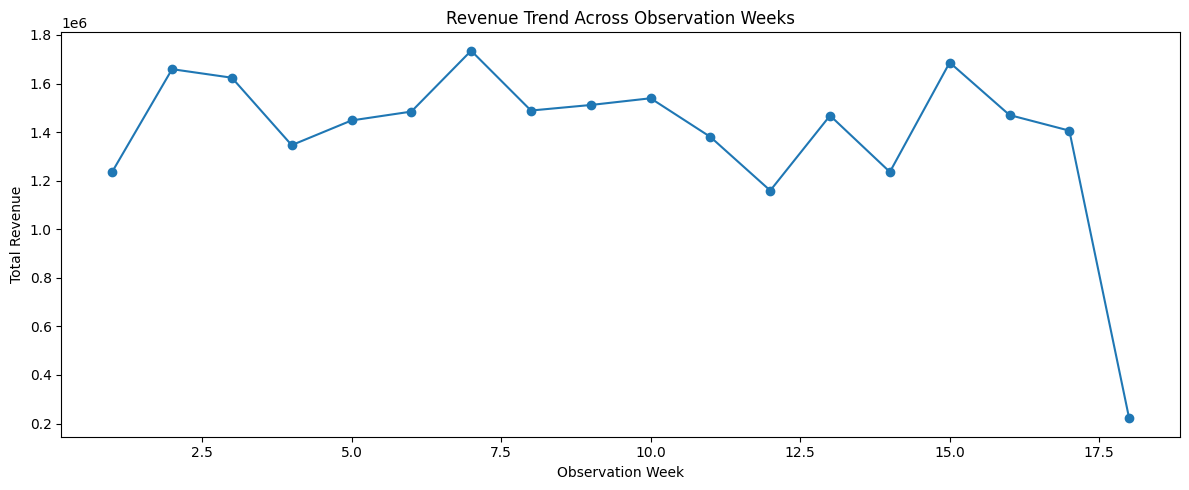

In [12]:

release_analysis = (
    df.groupby("release_week", as_index=False)
    .agg(
        total_revenue=("revenue", "sum"),
        tickets_sold=("tickets_sold", "sum")
    )
)

# Sort by the numerical week number
release_analysis["_week_num"] = (
    release_analysis["release_week"]
    .str.extract(r"(\d+)")
    .astype(int)
)

release_analysis = release_analysis.sort_values("_week_num")

display(release_analysis.drop(columns="_week_num"))

plt.figure(figsize=(12, 5))
plt.plot(
    release_analysis["_week_num"],
    release_analysis["total_revenue"],
    marker="o"
)
plt.title("Revenue Trend Across Observation Weeks")
plt.xlabel("Observation Week")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


Feature Engineering


In [13]:

# Step 5: Feature Engineering

import numpy as np
import pandas as pd
from IPython.display import display

# Create a copy of the merged EDA dataset
features_df = df.copy()

# 1. Extract month from show date
features_df["month"] = features_df["show_date"].dt.month

# 2. Extract day of the week
features_df["day_of_week"] = features_df["show_date"].dt.day_name()

# 3. Categorize showtime
def categorize_showtime(time):
    hour = int(str(time).split(":")[0])

    if hour < 12:
        return "Morning"
    elif hour < 17:
        return "Afternoon"
    else:
        return "Evening"

features_df["show_period"] = (
    features_df["show_time"].apply(categorize_showtime)
)

# 4. Calculate revenue per ticket
features_df["revenue_per_ticket"] = (
    features_df["revenue"] / features_df["tickets_sold"]
).round(2)

# 5. Categorize occupancy
features_df["occupancy_category"] = pd.cut(
    features_df["occupancy_percent"],
    bins=[-0.01, 30, 60, 80, 100],
    labels=["Low", "Moderate", "High", "Very High"]
)

# 6. Encode weekend as a binary feature
features_df["is_weekend"] = (
    features_df["day_type"] == "Weekend"
).astype(int)

# Display engineered features
new_columns = [
    "show_date", "show_time", "show_period", "month",
    "day_of_week", "tickets_sold", "revenue",
    "revenue_per_ticket", "occupancy_percent",
    "occupancy_category", "is_weekend"
]

display(features_df[new_columns].head(10))

print("Total records:", len(features_df))
print("New features created successfully!")


,show_date,show_time,show_period,month,day_of_week,tickets_sold,revenue,revenue_per_ticket,occupancy_percent,occupancy_category,is_weekend
0,2026-04-10,09:00,Morning,4,Friday,120,21600.0,180.0,60.00,Moderate,0
1,2026-02-25,15:00,Afternoon,2,Wednesday,103,15759.0,153.0,85.83,Very High,0
2,2026-04-17,09:00,Morning,4,Friday,80,20000.0,250.0,40.00,Moderate,0
3,2026-03-25,15:00,Afternoon,3,Wednesday,144,22032.0,153.0,72.00,High,0
4,2026-03-23,18:00,Evening,3,Monday,90,16200.0,180.0,56.25,Moderate,0
5,2026-04-17,21:00,Evening,4,Friday,89,13617.0,153.0,74.17,High,0
6,2026-02-26,21:00,Evening,2,Thursday,127,19431.0,153.0,79.38,High,0
7,2026-01-21,18:00,Evening,1,Wednesday,40,10000.0,250.0,23.53,Low,0
8,2026-03-09,09:00,Morning,3,Monday,150,27000.0,180.0,68.18,High,0
9,2026-02-19,21:00,Evening,2,Thursday,101,18180.0,180.0,59.41,Moderate,0


Total records: 1451
New features created successfully!


In [14]:

# Choose input features and the target variable
selected_features = [
    "genre",
    "language",
    "city",
    "show_period",
    "seat_class",
    "offer",
    "day_type",
    "holiday",
    "tickets_sold",
    "screen_capacity",
    "occupancy_percent"
]

target = "revenue"

# Check whether selected columns are available
print("Selected input features:")
for column in selected_features:
    print("-", column)

print("\nTarget variable:", target)

# Prepare a modelling table and encode categorical columns
model_df = features_df[selected_features + [target]].copy()
model_df = pd.get_dummies(
    model_df,
    columns=[
        "genre", "language", "city", "show_period",
        "seat_class", "offer", "day_type"
    ],
    dtype=int
)

print("\nEncoded modelling dataset shape:", model_df.shape)
display(model_df.head())


Selected input features:
- genre
- language
- city
- show_period
- seat_class
- offer
- day_type
- holiday
- tickets_sold
- screen_capacity
- occupancy_percent

Target variable: revenue

Encoded modelling dataset shape: (1451, 40)


,holiday,tickets_sold,screen_capacity,occupancy_percent,revenue,genre_Action,genre_Adventure,genre_Animation,genre_Documentary,genre_Drama,...,show_period_Evening,show_period_Morning,seat_class_Premium,seat_class_Recliner,seat_class_Standard,offer_No Offer,offer_Student,offer_Weekend Deal,day_type_Weekday,day_type_Weekend
0,0,120,200,60.00,21600.0,0,0,0,0,0,...,0,1,0,0,1,1,0,0,1,0
1,0,103,120,85.83,15759.0,1,0,0,0,0,...,0,0,0,0,1,0,0,1,1,0
2,0,80,200,40.00,20000.0,1,0,0,0,0,...,0,1,1,0,0,1,0,0,1,0
3,0,144,200,72.00,22032.0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,1,0
4,0,90,160,56.25,16200.0,0,0,0,0,0,...,1,0,0,0,1,1,0,0,1,0


Create the Excel analysis workbook

In [15]:

import pandas as pd
import os

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.chart import BarChart, Reference
from openpyxl.utils import get_column_letter

# Create the Excel output path
excel_path = "/content/CH29_Cinema_Revenue_Analysis.xlsx"

# Use the cleaned and merged data from previous steps
analysis = df.copy()

# Ensure date is in datetime format
analysis["show_date"] = pd.to_datetime(analysis["show_date"])

# Create analysis tables
genre_summary = (
    analysis.groupby("genre", as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Tickets_Sold=("tickets_sold", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

showtime_summary = (
    analysis.groupby("show_time", as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Average_Occupancy=("occupancy_percent", "mean"),
        Tickets_Sold=("tickets_sold", "sum")
    )
)
showtime_summary["Average_Occupancy"] = (
    showtime_summary["Average_Occupancy"].round(2)
)

weekend_summary = (
    analysis.groupby("day_type", as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Tickets_Sold=("tickets_sold", "sum"),
        Average_Occupancy=("occupancy_percent", "mean")
    )
)
weekend_summary["Average_Occupancy"] = (
    weekend_summary["Average_Occupancy"].round(2)
)

cinema_summary = (
    analysis.groupby(["cinema", "city"], as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Tickets_Sold=("tickets_sold", "sum"),
        Average_Occupancy=("occupancy_percent", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)
cinema_summary["Average_Occupancy"] = (
    cinema_summary["Average_Occupancy"].round(2)
)

offer_summary = (
    analysis.groupby("offer", as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Tickets_Sold=("tickets_sold", "sum"),
        Booking_Records=("booking_id", "count")
    )
)
offer_summary["Average_Revenue_Per_Ticket"] = (
    offer_summary["Total_Revenue"] / offer_summary["Tickets_Sold"]
).round(2)

release_summary = (
    analysis.groupby("release_week", as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Tickets_Sold=("tickets_sold", "sum")
    )
)

# Save all sheets into one workbook
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    analysis.to_excel(writer, sheet_name="Cleaned Data", index=False)
    genre_summary.to_excel(writer, sheet_name="Genre Analysis", index=False)
    showtime_summary.to_excel(writer, sheet_name="Showtime Analysis", index=False)
    weekend_summary.to_excel(writer, sheet_name="Weekend Analysis", index=False)
    cinema_summary.to_excel(writer, sheet_name="Cinema Analysis", index=False)
    offer_summary.to_excel(writer, sheet_name="Offer Analysis", index=False)
    release_summary.to_excel(writer, sheet_name="Weekly Trend", index=False)

# Format worksheets and add charts
wb = load_workbook(excel_path)

for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions

    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill(
            fill_type="solid", fgColor="1F4E78"
        )
        cell.alignment = Alignment(horizontal="center")

    for column_cells in ws.columns:
        max_length = max(
            len(str(cell.value)) if cell.value is not None else 0
            for cell in column_cells
        )
        ws.column_dimensions[
            get_column_letter(column_cells[0].column)
        ].width = min(max_length + 3, 28)

# Add a revenue chart to the genre sheet
ws = wb["Genre Analysis"]
chart = BarChart()
chart.type = "bar"
chart.style = 10
chart.title = "Revenue by Movie Genre"
chart.x_axis.title = "Revenue"
chart.y_axis.title = "Genre"
data = Reference(ws, min_col=2, min_row=1, max_row=ws.max_row)
cats = Reference(ws, min_col=1, min_row=2, max_row=ws.max_row)
chart.add_data(data, titles_from_data=True)
chart.set_categories(cats)
ws.add_chart(chart, "E2")

# Add a revenue chart to the cinema sheet
ws = wb["Cinema Analysis"]
chart = BarChart()
chart.type = "bar"
chart.style = 10
chart.title = "Revenue by Cinema"
chart.x_axis.title = "Revenue"
chart.y_axis.title = "Cinema"
data = Reference(ws, min_col=3, min_row=1, max_row=ws.max_row)
cats = Reference(ws, min_col=1, min_row=2, max_row=ws.max_row)
chart.add_data(data, titles_from_data=True)
chart.set_categories(cats)
ws.add_chart(chart, "F2")

wb.save(excel_path)

print("Excel workbook created successfully!")
print("Worksheets:", wb.sheetnames)
print("File:", excel_path)


Excel workbook created successfully!
Worksheets: ['Cleaned Data', 'Genre Analysis', 'Showtime Analysis', 'Weekend Analysis', 'Cinema Analysis', 'Offer Analysis', 'Weekly Trend']
File: /content/CH29_Cinema_Revenue_Analysis.xlsx


In [16]:

from google.colab import files
files.download("/content/CH29_Cinema_Revenue_Analysis.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Select input features (exclude revenue-derived features)
input_cols = [
    "genre", "language", "city", "show_time",
    "seat_class", "offer", "tickets_sold",
    "screen_capacity", "holiday"
]

# Use show_period instead of show_time if needed
if "show_time" not in features_df.columns:
    input_cols[input_cols.index("show_time")] = "show_period"

input_cols = [c for c in input_cols if c in features_df.columns]
X = features_df[input_cols].copy()
y = features_df["revenue"]

# Convert categories into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=int)
X = X.fillna(0)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model = RandomForestRegressor(
    n_estimators=100, random_state=42
)
model.fit(X_train, y_train)

# Evaluate performance
predictions = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

RMSE: 726.69
R² Score: 0.994


In [18]:

import pandas as pd
import numpy as np
import os
from IPython.display import display

# Original and cleaned data locations
original_folder = "/content"
clean_folder = "/content/CH29_Cleaned_Data"

original_files = {
    "Bookings": "bookings.csv",
    "Movies": "movies.csv",
    "Cinemas": "cinemas.csv",
    "Pricing": "pricing.csv",
    "Calendar": "calendar.csv"
}

clean_files = {
    "Bookings": "bookings_cleaned.csv",
    "Movies": "movies_cleaned.csv",
    "Cinemas": "cinemas_cleaned.csv",
    "Pricing": "pricing_cleaned.csv",
    "Calendar": "calendar_cleaned.csv"
}

quality_summary = []
type_summary = []
missing_summary = []
duplicate_summary = []
outlier_summary = []

for name, filename in original_files.items():
    raw = pd.read_csv(os.path.join(original_folder, filename))
    cleaned = pd.read_csv(os.path.join(clean_folder, clean_files[name]))

    quality_summary.append({
        "Dataset": name,
        "Original_Rows": len(raw),
        "Cleaned_Rows": len(cleaned),
        "Rows_Removed": len(raw) - len(cleaned),
        "Original_Columns": len(raw.columns),
        "Cleaned_Columns": len(cleaned.columns)
    })

    for col in raw.columns:
        type_summary.append({
            "Dataset": name,
            "Column": col,
            "Data_Type": str(raw[col].dtype)
        })

        missing_summary.append({
            "Dataset": name,
            "Column": col,
            "Missing_Values": int(raw[col].isna().sum())
        })

    duplicate_summary.append({
        "Dataset": name,
        "Original_Duplicate_Rows": int(raw.duplicated().sum()),
        "Cleaned_Duplicate_Rows": int(cleaned.duplicated().sum())
    })

    # IQR-based outlier screening for numeric columns
    for col in raw.select_dtypes(include=np.number).columns:
        values = raw[col].dropna()
        if len(values) >= 4 and values.nunique() > 1:
            q1 = values.quantile(0.25)
            q3 = values.quantile(0.75)
            iqr = q3 - q1
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            count = int(((values < lower) | (values > upper)).sum())

            outlier_summary.append({
                "Dataset": name,
                "Column": col,
                "IQR_Lower_Bound": round(lower, 2),
                "IQR_Upper_Bound": round(upper, 2),
                "Potential_Outlier_Count": count
            })

quality_df = pd.DataFrame(quality_summary)
types_df = pd.DataFrame(type_summary)
missing_df = pd.DataFrame(missing_summary)
duplicates_df = pd.DataFrame(duplicate_summary)
outliers_df = pd.DataFrame(outlier_summary)

print("DATASET ROW SUMMARY")
display(quality_df)

print("DATA TYPES")
display(types_df)

print("MISSING VALUES IN ORIGINAL DATA")
display(missing_df[missing_df["Missing_Values"] > 0])

print("DUPLICATE ROW SUMMARY")
display(duplicates_df)

print("POTENTIAL NUMERIC OUTLIERS (IQR METHOD)")
display(outliers_df)

# Save evidence tables
report_path = "/content/CH29_Data_Quality_Report.xlsx"

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    quality_df.to_excel(writer, sheet_name="Row Summary", index=False)
    types_df.to_excel(writer, sheet_name="Data Types", index=False)
    missing_df.to_excel(writer, sheet_name="Missing Values", index=False)
    duplicates_df.to_excel(writer, sheet_name="Duplicates", index=False)
    outliers_df.to_excel(writer, sheet_name="Potential Outliers", index=False)

print("\nData quality report saved:", report_path)


DATASET ROW SUMMARY


,Dataset,Original_Rows,Cleaned_Rows,Rows_Removed,Original_Columns,Cleaned_Columns
0,Bookings,1501,1451,50,10,10
1,Movies,20,20,0,6,6
2,Cinemas,8,8,0,4,4
3,Pricing,9,9,0,4,4
4,Calendar,120,120,0,4,4


DATA TYPES


,Dataset,Column,Data_Type
0,Bookings,booking_id,object
1,Bookings,cinema_id,object
2,Bookings,movie_id,object
3,Bookings,show_date,object
4,Bookings,show_time,object
5,Bookings,screen_id,object
6,Bookings,seat_class,object
7,Bookings,offer,object
8,Bookings,tickets_sold,int64
9,Bookings,revenue,float64


MISSING VALUES IN ORIGINAL DATA


...

DUPLICATE ROW SUMMARY


,Dataset,Original_Duplicate_Rows,Cleaned_Duplicate_Rows
0,Bookings,1,0
1,Movies,0,0
2,Cinemas,0,0
3,Pricing,0,0
4,Calendar,0,0


POTENTIAL NUMERIC OUTLIERS (IQR METHOD)


,Dataset,Column,IQR_Lower_Bound,IQR_Upper_Bound,Potential_Outlier_Count
0,Bookings,tickets_sold,-44.50,215.50,1
1,Bookings,revenue,-8662.50,41773.50,31
2,Movies,runtime_minutes,110.38,175.38,5
3,Cinemas,screen_capacity,91.25,241.25,0
4,Pricing,ticket_price,-75.00,605.00,0
5,Pricing,discount_percent,-22.50,37.50,0
6,Calendar,holiday,-1.50,2.50,0



Data quality report saved: /content/CH29_Data_Quality_Report.xlsx


In [19]:

# Validate the occupancy and observation-week fields

print("Occupancy checks")
print("Minimum occupancy (%):", df["occupancy_percent"].min())
print("Maximum occupancy (%):", df["occupancy_percent"].max())
print("Missing occupancy values:", df["occupancy_percent"].isna().sum())

print("\nObservation period")
print("First show date:", df["show_date"].min())
print("Last show date:", df["show_date"].max())
print("Unique observation weeks:", df["release_week"].nunique())

# Compare showtimes using the existing approximate measure
showtime_validation = (
    df.groupby("show_time", as_index=False)
    .agg(
        Booking_Records=("booking_id", "count"),
        Total_Tickets=("tickets_sold", "sum"),
        Mean_Booking_Occupancy=("occupancy_percent", "mean")
    )
    .sort_values("Mean_Booking_Occupancy", ascending=False)
)

display(showtime_validation.round(2))

# Compare observation weeks
weekly_validation = (
    df.groupby("release_week", as_index=False)
    .agg(
        Booking_Records=("booking_id", "count"),
        Total_Tickets=("tickets_sold", "sum"),
        Total_Revenue=("revenue", "sum")
    )
)

display(weekly_validation.head(10))

print("""
Interpretation limitations:
1. Occupancy uses listed cinema capacity as a proxy because
   screen-specific capacity and unique show IDs are unavailable.
2. Release week is an observation-period week, not a verified
   movie release week.
3. These are synthetic data results, not real cinema performance.
""")


Occupancy checks
Minimum occupancy (%): 9.09
Maximum occupancy (%): 100.0
Missing occupancy values: 0

Observation period
First show date: 2026-01-01 00:00:00
Last show date: 2026-04-30 00:00:00
Unique observation weeks: 18


,show_time,Booking_Records,Total_Tickets,Mean_Booking_Occupancy
3,18:00,276,24400,54.06
4,21:00,308,25595,50.99
0,09:00,289,24128,50.91
2,15:00,303,24688,49.81
1,12:00,275,22119,48.88


,release_week,Booking_Records,Total_Tickets,Total_Revenue
0,Week 1,70,6057,1236758.5
1,Week 10,86,7152,1539268.5
2,Week 11,80,6816,1380012.0
3,Week 12,69,5744,1159230.0
4,Week 13,84,6948,1468041.5
5,Week 14,75,6462,1235844.0
6,Week 15,96,8161,1686492.0
7,Week 16,77,7131,1470182.5
8,Week 17,77,6501,1405970.5
9,Week 18,17,1132,221389.0



Interpretation limitations:
1. Occupancy uses listed cinema capacity as a proxy because
   screen-specific capacity and unique show IDs are unavailable.
2. Release week is an observation-period week, not a verified
   movie release week.
3. These are synthetic data results, not real cinema performance.



,tickets_sold,revenue,occupancy_percent,screen_capacity,holiday
tickets_sold,1.00,0.84,0.92,0.03,-0.02
revenue,0.84,1.00,0.77,0.03,-0.03
occupancy_percent,0.92,0.77,1.00,-0.33,-0.02
screen_capacity,0.03,0.03,-0.33,1.00,-0.01
holiday,-0.02,-0.03,-0.02,-0.01,1.00


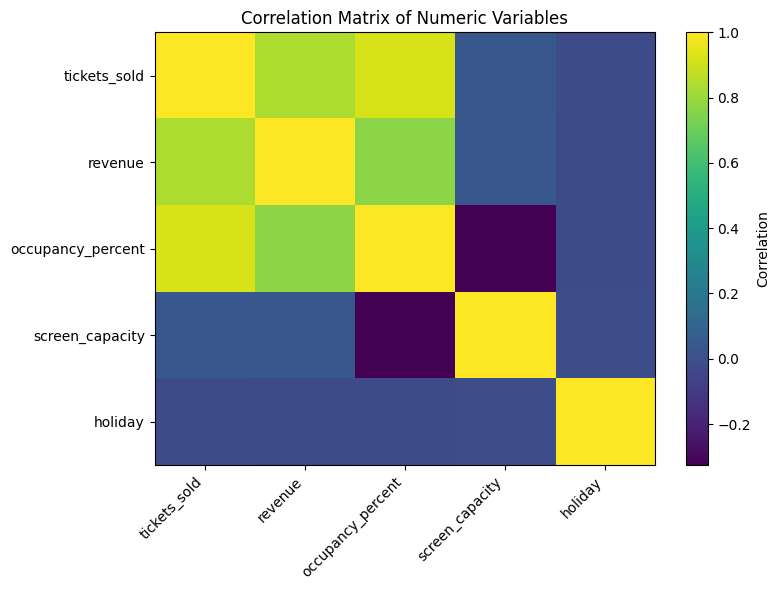

In [20]:

import matplotlib.pyplot as plt

numeric_columns = [
    "tickets_sold",
    "revenue",
    "occupancy_percent",
    "screen_capacity",
    "holiday"
]

correlation_matrix = df[numeric_columns].corr(numeric_only=True)

display(correlation_matrix.round(2))

plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(numeric_columns)),
    numeric_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(numeric_columns)), numeric_columns)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()


In [21]:

# Feature selection using absolute correlation with revenue.
# This is exploratory screening, not proof of predictive value.

selection_data = features_df[
    [
        "tickets_sold",
        "screen_capacity",
        "occupancy_percent",
        "month",
        "is_weekend",
        "revenue"
    ]
].copy()

selection_data = selection_data.replace([np.inf, -np.inf], np.nan)
selection_data = selection_data.dropna()

correlations = (
    selection_data.corr(numeric_only=True)["revenue"]
    .drop("revenue")
    .to_frame("Correlation_with_Revenue")
)

correlations["Absolute_Correlation"] = (
    correlations["Correlation_with_Revenue"].abs()
)

correlations = correlations.sort_values(
    "Absolute_Correlation", ascending=False
)

display(correlations.round(3))

print("""
Feature selection method:
Numeric features were ranked by their absolute Pearson correlation
with revenue. This provides an initial screening only.

Limitation:
Revenue is derived from ticket counts, prices and discounts.
Correlations do not establish causation or prove model performance.
""")


,Correlation_with_Revenue,Absolute_Correlation
tickets_sold,0.837,0.837
occupancy_percent,0.768,0.768
month,0.036,0.036
screen_capacity,0.034,0.034
is_weekend,-0.025,0.025



Feature selection method:
Numeric features were ranked by their absolute Pearson correlation
with revenue. This provides an initial screening only.

Limitation:
Revenue is derived from ticket counts, prices and discounts.
Correlations do not establish causation or prove model performance.



In [22]:

import zipfile
import os

evidence_folder = "/content/CH29_Round2_Evidence"
os.makedirs(evidence_folder, exist_ok=True)

features_df.to_csv(
    f"{evidence_folder}/engineered_features.csv",
    index=False
)

correlations.to_csv(
    f"{evidence_folder}/feature_selection_correlations.csv"
)

correlation_matrix.to_csv(
    f"{evidence_folder}/numeric_correlation_matrix.csv"
)

showtime_validation.to_csv(
    f"{evidence_folder}/showtime_validation.csv",
    index=False
)

weekly_validation.to_csv(
    f"{evidence_folder}/observation_week_analysis.csv",
    index=False
)

# Include the existing cleaned CSV files
for filename in [
    "bookings_cleaned.csv",
    "movies_cleaned.csv",
    "cinemas_cleaned.csv",
    "pricing_cleaned.csv",
    "calendar_cleaned.csv"
]:
    source = f"/content/CH29_Cleaned_Data/{filename}"
    if os.path.exists(source):
        import shutil
        shutil.copy2(source, evidence_folder)

# Include the data quality report
if os.path.exists("/content/CH29_Data_Quality_Report.xlsx"):
    import shutil
    shutil.copy2(
        "/content/CH29_Data_Quality_Report.xlsx",
        evidence_folder
    )

zip_path = "/content/CH29_Round2_Evidence.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_list in os.walk(evidence_folder):
        for filename in files_list:
            full_path = os.path.join(root, filename)
            z.write(
                full_path,
                arcname=os.path.relpath(full_path, evidence_folder)
            )

print("Round 2 evidence package created:", zip_path)


Round 2 evidence package created: /content/CH29_Round2_Evidence.zip


In [23]:

from google.colab import files
files.download("/content/CH29_Round2_Evidence.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>